# <u>Proyecto</u>: Análisis estadístico de series temporales ambientales de reservas de museos para la conservación preventiva sostenible de obras de arte

## 03. Objetivo 2 — Relación temporal entre la temperatura interior y exterior

**Objetivo específico**

> Analizar la dinámica entre las condiciones ambientales interiores y exteriores, con especial atención a la inercia térmica, al comportamiento de la humedad relativa y a la relación con variables meteorológicas externas.

<u>Alcance de este notebook</u>: Se desarrolla la **etapa exploratoria de temperatura (T)** del Objetivo 2. Se comparan niveles y fluctuaciones contemporáneas y se estudian asociaciones rezagadas mediante correlaciones cruzadas (CCF) con preblanqueo. El modelado dinámico conjunto y el análisis interior–exterior de humedad relativa (HR) no forman parte de esta versión.

El Objetivo 1 caracterizó cada serie a partir de su propio comportamiento temporal. Acá el foco pasa a la relación **interior–exterior**. Se utilizan las observaciones disponibles del monitoreo, no solamente los candidatos de anomalía detectados previamente.

## Índice

1. ¿Qué observaciones interiores y exteriores pueden compararse?
2. ¿En qué se diferencian los niveles y las fluctuaciones térmicas?
3. ¿Cómo se relacionan los cambios interiores y exteriores a distintos rezagos?
4. Síntesis del análisis interior–exterior
5. Referencias


## 1. ¿Qué observaciones interiores y exteriores pueden compararse?

> **Pregunta rectora:** ¿qué registros de temperatura pueden sincronizarse sin confundir cambios de ubicación, diferencias temporales y faltantes?

Se mantienen las cinco condiciones de medición definidas en el Objetivo 1: H1, H2-1, H2-2, H3 y H4.

Las observaciones interiores se emparejan con la temperatura exterior del SMN utilizando fechas y horas idénticas. No se imputan valores faltantes ni se considera consecutivo un par de observaciones separado por una interrupción.

Esta distinción permite comparar las condiciones observadas y, después, construir cambios y rezagos únicamente a partir de las horas realmente disponibles.

In [1]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.stats.diagnostic import acorr_ljungbox

In [2]:
pd.options.display.max_columns = 35

In [3]:
df = pd.read_csv(
    "../data/processed/sivori_horario_procesado.csv",
    sep=",",
    index_col="fecha",
    parse_dates=["fecha"],
)

eventos = pd.read_csv("../data/metadata/eventos_conocidos.csv")


In [4]:
HOBOS = ["H1", "H2", "H3", "H4"]

TEMP_INTERIOR = {hobo: f"{hobo} T (°C)" for hobo in HOBOS}
HR_INTERIOR = {hobo: f"{hobo} HRCal (%)" for hobo in HOBOS}

COLUMNA_T_EXT = "SMN T (°C)"

COLORES = {
    "H1": "#0072B2",
    "H2": "#D55E00",
    "H3": "#009E73",
    "H4": "#CC79A7",
    "SMN": "#7F7F7F",
}


In [5]:
def fin_de_dia(fecha):
    return pd.Timestamp(fecha).normalize() + pd.Timedelta(hours=23)


evento_h2 = eventos.loc[
    (eventos["tipo"] == "cambio_ubicacion")
    & eventos["sensor"].astype(str).str.contains("H2", na=False)
].iloc[0]

inicio_transicion_h2 = pd.Timestamp(evento_h2["inicio"])
fin_transicion_h2 = fin_de_dia(evento_h2["fin"])

inicio_monitoreo = df.index.min()
fin_monitoreo = df.index.max()

unidades_analisis = pd.DataFrame(
    [
        {
            "unidad": "H1",
            "sensor": "H1",
            "inicio": inicio_monitoreo,
            "fin": fin_monitoreo,
            "H2_post": 0,
        },
        {
            "unidad": "H2-1",
            "sensor": "H2",
            "inicio": inicio_monitoreo,
            "fin": inicio_transicion_h2 - pd.Timedelta(hours=1),
            "H2_post": 0,
        },
        {
            "unidad": "H2-2",
            "sensor": "H2",
            "inicio": fin_transicion_h2 + pd.Timedelta(hours=1),
            "fin": fin_monitoreo,
            "H2_post": 1,
        },
        {
            "unidad": "H3",
            "sensor": "H3",
            "inicio": inicio_monitoreo,
            "fin": fin_monitoreo,
            "H2_post": 0,
        },
        {
            "unidad": "H4",
            "sensor": "H4",
            "inicio": inicio_monitoreo,
            "fin": fin_monitoreo,
            "H2_post": 0,
        },
    ]
).set_index("unidad")

display(unidades_analisis)


,sensor,inicio,fin,H2_post
unidad,,,,
H1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,0
H2-1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,0
H2-2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,1
H3,H3,2022-12-29 14:00:00,2024-01-04 14:00:00,0
H4,H4,2022-12-29 14:00:00,2024-01-04 14:00:00,0


### 1.1 Series por condición de medición

> **Pregunta rectora:** ¿cómo se construyen las series comparables respetando la reubicación de H2 y los períodos efectivamente registrados?

H2 se divide en dos condiciones espaciales y se excluye la ventana de transición documentada. H1, H3 y H4 mantienen una única condición cada uno, con sus respectivos faltantes. A partir de esas series se construyen pares simultáneos de T interior y exterior.


In [6]:
def serie_unidad(unidad, columnas):
    fila = unidades_analisis.loc[unidad]
    sensor = fila["sensor"]

    serie = df.loc[
        fila["inicio"]:fila["fin"],
        columnas[sensor],
    ].astype(float)

    disponible = f"{sensor}_disponible"
    if disponible in df.columns:
        mascara = df.loc[serie.index, disponible].fillna(False).astype(bool)
        serie = serie.where(mascara)

    return serie


series_t = {
    unidad: serie_unidad(unidad, TEMP_INTERIOR)
    for unidad in unidades_analisis.index
}

serie_t_ext = df[COLUMNA_T_EXT].astype(float)


In [7]:
def sincronizar_interior_exterior(serie_interior, serie_exterior):
    datos = pd.concat(
        [
            serie_interior.rename("T_int"),
            serie_exterior.rename("T_ext"),
        ],
        axis=1,
        join="inner",
        sort=False,
    ).sort_index()

    return datos.dropna()


def bloques_continuos_df(datos, paso="1h"):
    if datos.empty:
        return []

    paso = pd.Timedelta(paso)
    grupos = datos.index.to_series().diff().ne(paso).cumsum()

    return [
        bloque.copy()
        for _, bloque in datos.groupby(grupos)
    ]


pares_t = {
    unidad: sincronizar_interior_exterior(
        serie,
        serie_t_ext,
    )
    for unidad, serie in series_t.items()
}


### 1.2 Cobertura conjunta y continuidad

> **Pregunta rectora:** ¿cuántas horas compartidas quedan disponibles y cómo se distribuyen las interrupciones?

La cobertura se calcula sobre el intervalo cronológico de cada condición, mientras que los bloques continuos identifican tramos en los que pueden calcularse diferencias y rezagos sin atravesar faltantes. Se informa el número de observaciones simultáneas, su porcentaje respecto del intervalo esperado y la extensión del bloque continuo más largo.


In [8]:
def resumen_cobertura_interior_exterior(pares):
    filas = []

    for unidad, datos in pares.items():
        fila = unidades_analisis.loc[unidad]
        sensor = fila["sensor"]

        indice_esperado = pd.date_range(
            fila["inicio"],
            fila["fin"],
            freq="h",
        )

        n_intervalo = len(indice_esperado)
        bloques = bloques_continuos_df(datos)

        filas.append({
            "unidad": unidad,
            "sensor": sensor,
            "inicio": fila["inicio"],
            "fin": fila["fin"],
            "n_horas_intervalo": n_intervalo,
            "n_comunes": len(datos),
            "pct_cobertura_intervalo": (
                100 * len(datos) / n_intervalo
                if n_intervalo
                else np.nan
            ),
            "n_bloques_continuos": len(bloques),
            "bloque_continuo_max_h": max(
                (len(b) for b in bloques),
                default=0,
            ),
        })

    return pd.DataFrame(filas).set_index("unidad")


cobertura_t_int_ext = resumen_cobertura_interior_exterior(pares_t)
display(cobertura_t_int_ext)


,sensor,inicio,fin,n_horas_intervalo,n_comunes,pct_cobertura_intervalo,n_bloques_continuos,bloque_continuo_max_h
unidad,,,,,,,,
H1,H1,2022-12-29 14:00:00,2024-01-04 14:00:00,8905,8872,99.629422,4,3190
H2-1,H2,2022-12-29 14:00:00,2023-04-07 23:00:00,2386,2385,99.958089,2,1849
H2-2,H2,2023-04-15 00:00:00,2024-01-04 14:00:00,6351,6350,99.984254,2,5206
H3,H3,2022-12-29 14:00:00,2024-01-04 14:00:00,8905,7823,87.849523,5,1985
H4,H4,2022-12-29 14:00:00,2024-01-04 14:00:00,8905,7603,85.379001,4,3190


In [9]:
def diagnostico_timestamps(datos):
    indice = datos.index

    return {
        "n": len(indice),
        "duplicados": int(indice.duplicated().sum()),
        "n_bloques": len(bloques_continuos_df(datos)),
    }


diagnostico_tiempos = pd.DataFrame({
    unidad: diagnostico_timestamps(datos)
    for unidad, datos in pares_t.items()
}).T

display(diagnostico_tiempos)


,n,duplicados,n_bloques
H1,8872,0,4
H2-1,2385,0,2
H2-2,6350,0,2
H3,7823,0,5
H4,7603,0,4


### 1.3 Inspección visual de sincronización

La comparación gráfica de ambas temperaturas en una misma ventana sirve para comprobar la alineación de fechas y la coherencia general de los registros.

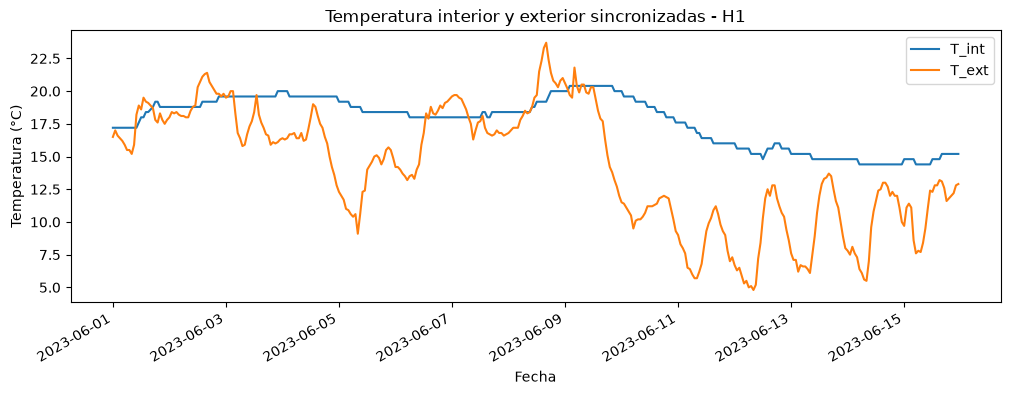

In [10]:
def graficar_sincronizacion(datos, unidad, inicio=None, fin=None):
    muestra = datos.loc[inicio:fin]

    ax = muestra.plot(
        figsize=(12, 4),
        ylabel="Temperatura (°C)",
        title=f"Temperatura interior y exterior sincronizadas - {unidad}",
    )

    ax.set_xlabel("Fecha")
    plt.show()


graficar_sincronizacion(
    pares_t["H1"],
    unidad="H1",
    inicio="2023-06-01",
    fin="2023-06-15",
)


### 1.4 Síntesis de la compatibilización

Los pares de observaciones simultáneas tienen una cobertura prácticamente completa en H1 y H2 (superior al 99 % en sus respectivos intervalos). En H3 y H4 la cobertura es menor, aproximadamente **87,85 % y 85,38 %**, debido a las interrupciones del monitoreo. No se identifican timestamps duplicados en los pares sincronizados.

## 2. ¿En qué se diferencian los niveles y las fluctuaciones térmicas?

> **Pregunta rectora:** ¿el ambiente interior registra temperaturas y variaciones de magnitud semejante a las exteriores, y esa relación cambia según la escala temporal?

Antes de considerar posibles retrasos, se examinan tres aspectos descriptivos:

1. **Nivel:** diferencia simultánea entre T interior y exterior.
2. **Fluctuación:** magnitud de los cambios observados en horizontes de 1, 3, 6, 12 y 24 horas.
3. **Asociación contemporánea:** correlación entre cambios calculados sobre el mismo intervalo.

La distinción es relevante porque temperaturas interiores relativamente estables pueden coexistir con variaciones exteriores intensas y con respuestas interiores que no ocurren en la misma hora.


### 2.1 Diferencia de nivel interior–exterior

> **Pregunta rectora:** ¿cuánto difiere la temperatura interior de la exterior cuando ambas se observan en el mismo instante?

Para cada condición se calcula:

$$
D_t=T_t^{int}-T_t^{ext}.
$$

Se resumen su mediana, rango intercuartílico y proporción de horas en las que la temperatura interior supera a la exterior. También se examina la evolución de la diferencia a escala mensual.


In [11]:
def resumir_diferencia_niveles(pares):
    filas = []

    for unidad, datos in pares.items():
        d = (datos["T_int"] - datos["T_ext"]).dropna()

        filas.append({
            "unidad": unidad,
            "n": len(d),
            "T_int_mediana": datos["T_int"].median(),
            "T_ext_mediana": datos["T_ext"].median(),
            "dif_mediana": d.median(),
            "dif_q25": d.quantile(0.25),
            "dif_q75": d.quantile(0.75),
            "dif_p10": d.quantile(0.10),
            "dif_p90": d.quantile(0.90),
            "pct_int_mayor_ext": 100 * (d > 0).mean(),
        })

    return pd.DataFrame(filas).set_index("unidad")


resumen_niveles_int_ext = resumir_diferencia_niveles(pares_t)
display(resumen_niveles_int_ext.round(2))


,n,T_int_mediana,T_ext_mediana,dif_mediana,dif_q25,dif_q75,dif_p10,dif_p90,pct_int_mayor_ext
unidad,,,,,,,,,
H1,8872,20.00,18.5,2.10,0.30,3.90,-1.51,5.90,78.07
H2-1,2385,27.78,25.2,2.15,0.45,3.73,-1.56,5.26,79.25
H2-2,6350,18.79,16.3,2.92,0.99,4.97,-0.90,6.90,83.67
H3,7823,22.39,19.5,3.59,1.42,6.03,-0.48,8.43,87.08
H4,7603,21.74,19.8,2.27,0.35,4.20,-1.50,6.33,78.36


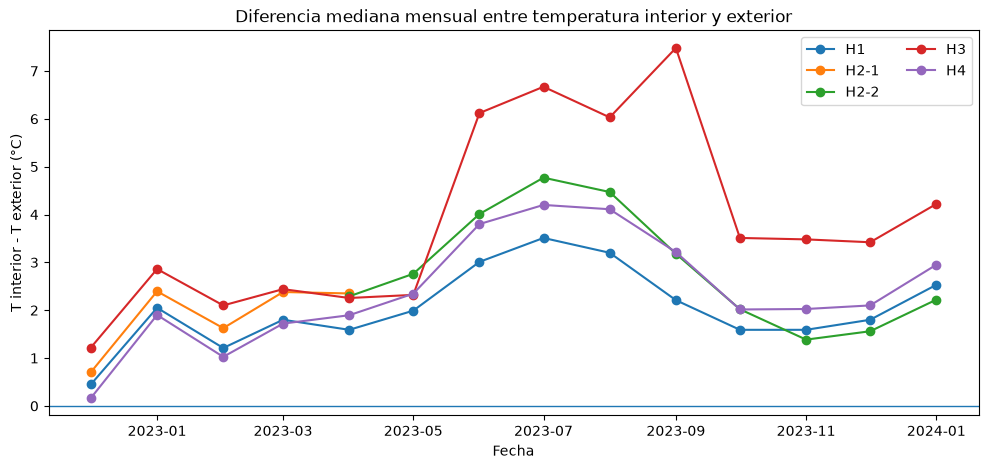

In [12]:
def diferencia_mensual(pares):
    partes = []

    for unidad, datos in pares.items():
        aux = datos.copy()
        aux["diferencia"] = aux["T_int"] - aux["T_ext"]

        mensual = (
            aux["diferencia"]
            .resample("MS")
            .median()
            .rename("dif_mediana")
            .to_frame()
        )

        mensual["unidad"] = unidad
        partes.append(mensual.reset_index())

    return pd.concat(partes, ignore_index=True)


dif_mensual = diferencia_mensual(pares_t)

fig, ax = plt.subplots(figsize=(12, 5))

for unidad, grupo in dif_mensual.groupby("unidad"):
    ax.plot(
        grupo["fecha"],
        grupo["dif_mediana"],
        marker="o",
        label=unidad,
    )

ax.axhline(0, linewidth=1)
ax.set_title("Diferencia mediana mensual entre temperatura interior y exterior")
ax.set_xlabel("Fecha")
ax.set_ylabel("T interior - T exterior (°C)")
ax.legend(ncol=2)
plt.show()


En todas las condiciones, la mediana de la diferencia $T^{int}-T^{ext}$ es positiva: varía aproximadamente entre **2,10 °C en H1** y **3,59 °C en H3**. La temperatura interior supera a la exterior entre el **78 % y el 87 %** de las observaciones simultáneas, según la condición.

La diferencia entre las temperaturas interiores y exteriores también presenta variaciones mensuales, por lo que la separación observada no es uniforme a lo largo del período de monitoreo.

### 2.2 Fluctuaciones a distintas escalas

> **Pregunta rectora:** ¿cuánto cambian las temperaturas interior y exterior cuando se comparan horas separadas por distintos horizontes?

Para un horizonte $h$, se calcula:

$$
\Delta_h T_t=T_t-T_{t-h}.
$$

El cálculo exige la existencia de ambos timestamps exactos; si falta $t-h$, el cambio no se calcula. Se comparan la mediana y el percentil 95 de $|\Delta_hT|$ para T interior y exterior, sin equiparar todavía las variaciones contemporáneas con una respuesta dinámica.


In [13]:
HORIZONTES = [1, 3, 6, 12, 24]


def cambios_exactos_interior_exterior(datos, horizonte_h):
    actual = datos[["T_int", "T_ext"]].copy()

    previo = actual.copy()
    previo.index = previo.index + pd.Timedelta(hours=horizonte_h)
    previo = previo.rename(columns={
        "T_int": "T_int_prev",
        "T_ext": "T_ext_prev",
    })

    pares = actual.join(previo, how="inner").dropna()

    pares["delta_int"] = pares["T_int"] - pares["T_int_prev"]
    pares["delta_ext"] = pares["T_ext"] - pares["T_ext_prev"]

    pares["abs_delta_int"] = pares["delta_int"].abs()
    pares["abs_delta_ext"] = pares["delta_ext"].abs()

    return pares


In [14]:
def resumir_cambios_interior_exterior(pares, horizontes):
    filas = []

    for unidad, datos in pares.items():
        for h in horizontes:
            cambios = cambios_exactos_interior_exterior(datos, h)

            med_int = cambios["abs_delta_int"].median()
            med_ext = cambios["abs_delta_ext"].median()

            p95_int = cambios["abs_delta_int"].quantile(0.95)
            p95_ext = cambios["abs_delta_ext"].quantile(0.95)

            filas.append({
                "unidad": unidad,
                "horizonte_h": h,
                "n_pares": len(cambios),
                "med_abs_int": med_int,
                "med_abs_ext": med_ext,
                "p95_abs_int": p95_int,
                "p95_abs_ext": p95_ext,
                "razon_mediana_int_ext": (
                    med_int / med_ext
                    if med_ext > 0
                    else np.nan
                ),
                "razon_p95_int_ext": (
                    p95_int / p95_ext
                    if p95_ext > 0
                    else np.nan
                ),
                "corr_cambios_contemporaneos": (
                    cambios["delta_int"].corr(cambios["delta_ext"])
                    if len(cambios) >= 2
                    else np.nan
                ),
            })

    return (
        pd.DataFrame(filas)
        .set_index(["unidad", "horizonte_h"])
        .sort_index()
    )


resumen_cambios_int_ext = resumir_cambios_interior_exterior(
    pares_t,
    HORIZONTES,
)

display(resumen_cambios_int_ext.round(3))


n_pares  med_abs_int  med_abs_ext  p95_abs_int  \
unidad horizonte_h                                                   
H1     1               8868         0.00          0.4        0.400   
       3               8864         0.00          1.1        0.410   
       6               8858         0.00          1.8        0.800   
       12              8846         0.40          2.5        1.200   
       24              8822         0.41          1.8        1.620   
H2-1   1               2383         0.00          0.5        0.420   
       3               2381         0.00          1.3        0.420   
       6               2378         0.00          2.2        0.810   
       12              2372         0.41          2.8        0.850   
       24              2360         0.42          1.5        1.270   
H2-2   1               6348         0.00          0.4        0.410   
       3               6346         0.40          1.0        0.810   
       6               6343         0.41          1.7        1.610   
       12              6337         0.80          2.4        2.030   
       24              6325         0.80          1.9        2.030   
H3     1               7818         0.00          0.4        0.400   
       3               7812         0.00          1.1        0.400   
       6               7803         0.00          1.8        0.420   
       12              7785         0.40          2.5        0.820   
       24              7749         0.40          1.7        1.226   
H4     1               7599         0.03          0.4        0.100   
       3               7595         0.07          1.1        0.240   
       6               7589         0.12          1.9        0.420   
       12              7577         0.22          2.6        0.740   
       24              7553         0.39          1.7        1.310   

                    p95_abs_ext  razon_mediana_int_ext  razon_p95_int_ext  \
unidad horizonte_h                                                          
H1     1                   1.60                  0.000              0.250   
       3                   3.70                  0.000              0.111   
       6                   5.70                  0.000              0.140   
       12                  7.40                  0.160              0.162   
       24                  6.00                  0.228              0.270   
H2-1   1                   1.80                  0.000              0.233   
       3                   4.00                  0.000              0.105   
       6                   6.20                  0.000              0.131   
       12                  8.00                  0.146              0.106   
       24                  6.00                  0.280              0.212   
H2-2   1                   1.50                  0.000              0.273   
       3                   3.50                  0.400              0.231   
       6                   5.50                  0.241              0.293   
       12                  7.10                  0.333              0.286   
       24                  6.00                  0.421              0.338   
H3     1                   1.60                  0.000              0.250   
       3                   3.60                  0.000              0.111   
       6                   5.60                  0.000              0.075   
       12                  7.28                  0.160              0.113   
       24                  6.00                  0.235              0.204   
H4     1                   1.70                  0.075              0.059   
       3                   3.70                  0.064              0.065   
       6                   5.80                  0.063              0.072   
       12                  7.40                  0.085              0.100   
       24                  5.90                  0.229              0.222   

                    corr_cambios_contemporaneos  

Las fluctuaciones térmicas interiores son menores que las exteriores en los horizontes examinados. A una hora, la mediana del cambio absoluto interior es **0 °C** en varias condiciones, mientras que la mediana exterior se sitúa aproximadamente entre **0,4 y 0,5 °C**. Esta diferencia debe leerse junto con la granularidad observada de H1–H3: un cambio registrado como nulo no necesariamente implica ausencia de variación física.

A horizontes más largos, las medianas interiores aumentan y los percentiles 95 permiten describir fluctuaciones que quedan ocultas por la acumulación de cambios horarios iguales a cero. H2-2 presenta mayores fluctuaciones interiores que las otras condiciones en varios horizontes.


### 2.3 Relación descriptiva entre las amplitudes

> **Pregunta rectora:** ¿qué fracción de la magnitud típica de las fluctuaciones exteriores se observa en el interior para un mismo horizonte?

Se utiliza la razón:

$$
A_h=\frac{\operatorname{mediana}(|\Delta_hT^{int}|)}
{\operatorname{mediana}(|\Delta_hT^{ext}|)}.
$$

Si $A_h<1$, la fluctuación interior típica es menor que la exterior a esa escala. Se trata de una comparación **descriptiva**, todavía sin alinear los posibles rezagos entre ambas series.


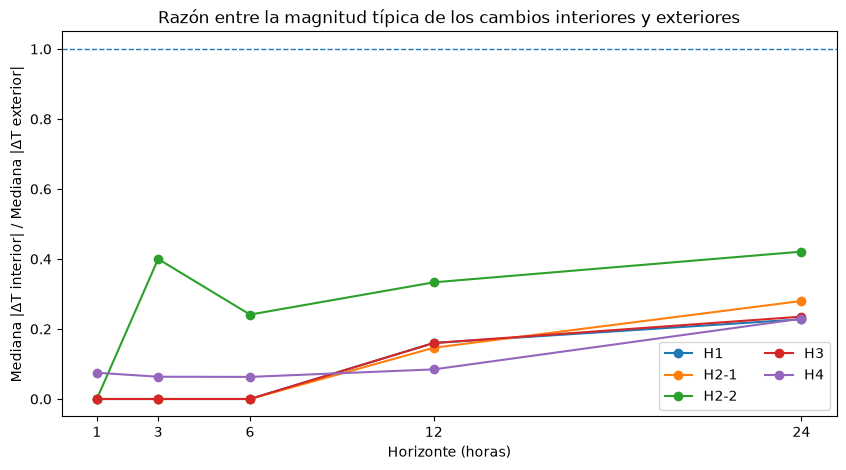

In [15]:
razones = (
    resumen_cambios_int_ext["razon_mediana_int_ext"]
    .unstack("unidad")
)

fig, ax = plt.subplots(figsize=(10, 5))

for unidad in razones.columns:
    ax.plot(
        razones.index,
        razones[unidad],
        marker="o",
        label=unidad,
    )

ax.axhline(1, linestyle="--", linewidth=1)
ax.set_title("Razón entre la magnitud típica de los cambios interiores y exteriores")
ax.set_xlabel("Horizonte (horas)")
ax.set_ylabel("Mediana |ΔT interior| / Mediana |ΔT exterior|")
ax.set_xticks(HORIZONTES)
ax.legend(ncol=2)

plt.show()


Las razones de amplitud son inferiores a 1 en las condiciones y horizontes examinados, lo que refleja fluctuaciones interiores típicamente menores que las exteriores. En varios casos, la razón a una hora es cero porque la mediana del cambio interior es nula; esto debe interpretarse a la luz de la granularidad térmica.

Las razones tienden a aumentar en horizontes más largos, aunque no de manera idéntica entre condiciones. No se consideran coeficientes físicos de amortiguación porque comparan cambios en el mismo intervalo, sin contemplar un posible desplazamiento temporal de la respuesta.


### 2.4 Asociación contemporánea entre los cambios

> **Pregunta rectora:** ¿las variaciones interiores y exteriores ocurren conjuntamente cuando se observan sobre el mismo intervalo temporal?

Se calcula la correlación de Pearson entre $\Delta_hT^{ext}$ y $\Delta_hT^{int}$ para cada horizonte $h$. Una correlación contemporánea baja no descarta que exista una asociación a rezagos posteriores.


In [16]:
corr_cambios = (
    resumen_cambios_int_ext["corr_cambios_contemporaneos"]
    .unstack("horizonte_h")
)

display(corr_cambios.round(3))


horizonte_h,1,3,6,12,24
unidad,,,,,
H1,-0.024,-0.040,-0.045,0.008,0.268
H2-1,0.089,0.130,0.128,0.135,0.220
H2-2,-0.014,-0.046,-0.027,0.056,0.296
H3,-0.033,-0.046,-0.055,-0.018,0.115
H4,0.008,-0.004,-0.013,-0.012,0.069


Las correlaciones contemporáneas a **1 hora** son pequeñas en todas las condiciones (aproximadamente entre **−0,033 y 0,089**). A **24 horas** aumentan en H1 (0,268), H2-1 (0,220) y H2-2 (0,296), mientras que permanecen más bajas en H3 (0,115) y H4 (0,069).

Esto muestra que la asociación contemporánea depende del horizonte y de la condición de medición. Para estudiar si los cambios exteriores preceden a los interiores, es necesario incorporar explícitamente los rezagos.


### 2.5 Síntesis

El interior presenta niveles térmicos generalmente superiores y fluctuaciones de menor magnitud que el exterior, aunque las diferencias dependen de la ubicación y del horizonte temporal.

La asociación entre cambios calculados en la misma hora es reducida, especialmente a horizontes cortos. Por ello, el análisis siguiente se concentra en la relación rezagada entre las variaciones exteriores e interiores, sin identificar una razón de amplitudes contemporánea con un parámetro de inercia térmica.


## 3. ¿Cómo se relacionan los cambios interiores y exteriores a distintos rezagos?

> **Pregunta rectora:** ¿en qué rezagos se concentran las asociaciones entre los cambios térmicos exteriores e interiores, una vez considerada la persistencia temporal del exterior?

Se calculan correlaciones cruzadas (CCF) entre cambios horarios de temperatura. Se adopta la convención **$k>0$: el cambio exterior antecede al interior**. Para limitar la influencia de la persistencia del exterior sobre estas correlaciones, se utiliza un filtro autorregresivo estimado sobre la serie exterior y aplicado después a las interiores.

### 3.1 Cambios horarios sincronizados

> **Pregunta rectora:** ¿qué diferencias horarias pueden calcularse sin cruzar interrupciones y cómo se compara su dispersión?

Se construyen cambios horarios mediante timestamps exactos. Esta transformación permite analizar las variaciones, en lugar de correlacionar series en nivel dominadas por la evolución anual.


In [17]:
LAG_MIN_CCF = -24
LAG_MAX_CCF = 48


def diferencia_exacta(serie, horizonte_h=1):
    s = serie.dropna().sort_index().astype(float)

    previa = s.copy()
    previa.index = previa.index + pd.Timedelta(hours=horizonte_h)

    pares = pd.concat(
        [
            s.rename("actual"),
            previa.rename("previa"),
        ],
        axis=1,
        sort=False,
    ).dropna()

    return pares["actual"] - pares["previa"]


dT_ext_full = diferencia_exacta(serie_t_ext, 1)

cambios_horarios_t = {}

for unidad, serie in series_t.items():
    dT_int = diferencia_exacta(serie, 1)

    cambios_horarios_t[unidad] = pd.concat(
        [
            dT_int.rename("dT_int"),
            dT_ext_full.rename("dT_ext"),
        ],
        axis=1,
        sort=False,
    ).dropna()


In [18]:
resumen_cambios_horarios = pd.DataFrame({
    unidad: {
        "n": len(datos),
        "sd_dT_ext": datos["dT_ext"].std(),
        "sd_dT_int": datos["dT_int"].std(),
    }
    for unidad, datos in cambios_horarios_t.items()
}).T

display(resumen_cambios_horarios.round(3))


,n,sd_dT_ext,sd_dT_int
H1,8868.0,0.817,0.141
H2-1,2383.0,0.918,0.142
H2-2,6348.0,0.775,0.211
H3,7818.0,0.817,0.130
H4,7599.0,0.826,0.056


La desviación estándar de los cambios horarios exteriores se sitúa entre **0,775 y 0,918 °C**, según el tramo considerado. En el interior es considerablemente menor: aproximadamente entre **0,056 °C en H4** y **0,211 °C en H2-2**.

Esta diferencia es consistente con la menor magnitud de las fluctuaciones interiores observada en la sección 2. La primera diferencia se examina a continuación antes de utilizarla en el preblanqueo.


### 3.2 Diagnóstico de estacionariedad: niveles y cambios horarios

> **Pregunta rectora:** ¿la primera diferencia horaria constituye una transformación razonable para estudiar la asociación rezagada entre temperaturas?

Se comparan las series en **nivel** y en **$\Delta_1 T_t=T_t-T_{t-1}$** mediante las pruebas ADF (hipótesis nula de raíz unitaria) y KPSS (hipótesis nula de estacionariedad de nivel), junto con la ACF a 1, 24 y 48 horas.

**Supuestos y alcance:** las pruebas se aplican al bloque horario continuo más largo de cada serie. Sus resultados son sensibles a tendencias, estacionalidad, cambios estructurales y tamaño muestral; por ello, se interpretan conjuntamente con las ACF. La estacionariedad no implica ausencia de autocorrelación: una serie diferenciada todavía puede conservar memoria diaria.


In [19]:
def bloque_mas_largo(serie):
    s = serie.dropna().sort_index().astype(float)
    if s.empty:
        return s
    grupos = s.index.to_series().diff().ne(pd.Timedelta(hours=1)).cumsum()
    return max((g for _, g in s.groupby(grupos)), key=len)


def diagnostico_estacionariedad_t(serie):
    bloque = bloque_mas_largo(serie)
    resultado = {'n':len(bloque), 'inicio': bloque.index.min() if len(bloque) else pd.NaT,
                 'fin': bloque.index.max() if len(bloque) else pd.NaT,
                 'adf_p':np.nan, 'kpss_p':np.nan, 'acf_1':np.nan, 'acf_24':np.nan,
                 'acf_48':np.nan}
    if len(bloque) < 120 or bloque.nunique() < 4:
        return resultado
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        try:
            resultado['adf_p'] = float(adfuller(bloque, regression='c',
                                            maxlag=24, autolag='AIC')[1])
        except (ValueError, np.linalg.LinAlgError):pass
        try:
            resultado['kpss_p'] = float(kpss(bloque, regression='c', nlags='auto')[1])
        except (ValueError, np.linalg.LinAlgError):pass
    rho = acf(bloque, nlags=48, fft=True)
    for k in (1,24,48):resultado[f'acf_{k}']=float(rho[k])
    return resultado

filas_estac = []
series_diag = {'Exterior SMN':serie_t_ext}
series_diag.update({f'Interior {u}':s for u,s in series_t.items()})
for etiqueta, serie in series_diag.items():
    for tr, candidata in [('Nivel', serie), ('Δ1h', diferencia_exacta(serie, 1))]:
        filas_estac.append({'serie':etiqueta, 'transformacion':tr,
                            **diagnostico_estacionariedad_t(candidata)})

diagnostico_estacionariedad_T = pd.DataFrame(filas_estac).set_index(['serie','transformacion'])
display(diagnostico_estacionariedad_T.style.format(precision=4))


**Autocorrelación antes y después de la diferencia.** Las ACF permiten examinar cuánto disminuye la dependencia en los primeros 48 rezagos y si permanece alguna asociación alrededor de 24 horas.

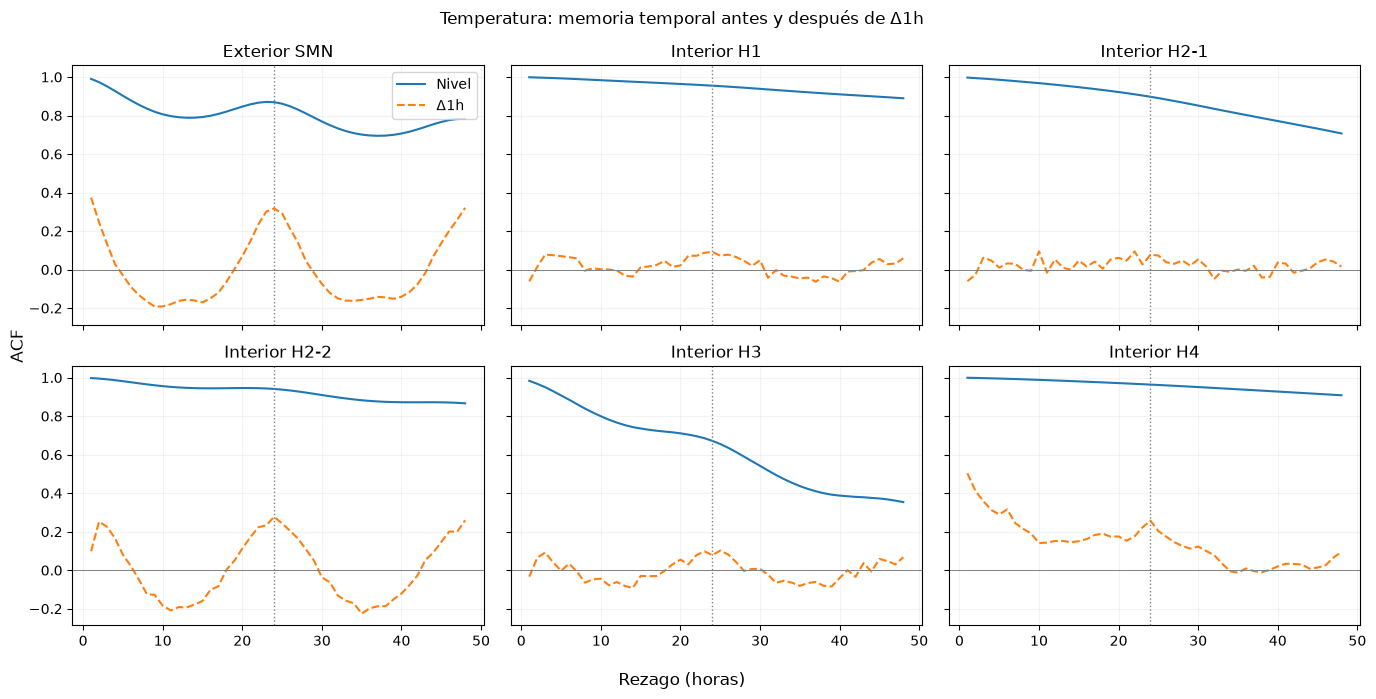

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True, sharey=True)
for ax, (nombre,s) in zip(axes.ravel(), series_diag.items()):
    for tr, candidata, estilo in [('Nivel',s,'-'), ('Δ1h',diferencia_exacta(s,1),'--')]:
        bloque = bloque_mas_largo(candidata)
        if len(bloque) > 50 and bloque.nunique() > 3:
            rho = acf(bloque, nlags=48, fft=True)
            ax.plot(range(1,49), rho[1:], linestyle=estilo, label=tr)
    ax.axvline(24, linestyle=':', color='gray', linewidth=1)
    ax.axhline(0, linewidth=.7, color='gray')
    ax.set_title(nombre)
    ax.grid(alpha=.15)
axes[0,0].legend()
fig.supxlabel('Rezago (horas)')
fig.supylabel('ACF')
fig.suptitle('Temperatura: memoria temporal antes y después de Δ1h')
plt.tight_layout()
plt.show()

En nivel, las series muestran autocorrelaciones muy elevadas y los contrastes ADF/KPSS ofrecen resultados heterogéneos, coherentes con la presencia de evolución temporal lenta. Después de la diferencia horaria, el diagnóstico es más compatible con estacionariedad: ADF rechaza la hipótesis de raíz unitaria y KPSS no rechaza la de estacionariedad al nivel de significación habitual en las series examinadas.

Sin embargo, **$\Delta_1 T$ no es ruido blanco**. En el exterior permanecen asociaciones apreciables a 24 y 48 horas (ACF cercana a 0,32). Por eso se conserva la primera diferencia como transformación común y se modela la dependencia residual exterior mediante un filtro AR, sin diferenciar estacionalmente de forma automática.


### 3.3 Selección acotada del filtro AR exterior

> **Pregunta rectora:** ¿qué filtro permite reducir la autocorrelación del cambio horario exterior antes de calcular la CCF?

Se ajustan modelos autorregresivos con órdenes $p\in\{12,24,48,72\}$ a la temperatura exterior diferenciada. La selección se realiza mediante el criterio de información bayesiano (BIC), calculado sobre una misma muestra efectiva para garantizar la comparabilidad entre candidatos.

In [21]:
CANDIDATOS_AR = (12, 24, 48, 72)
MAX_P_PREBLANQUEO = max(CANDIDATOS_AR)


def matriz_ar_exacta(serie, max_p):
    s = serie.dropna().sort_index().astype(float)
    s = s - s.mean()
    columnas = {'actual':s}
    for lag in range(1,max_p+1):
        rezagada=s.copy()
        rezagada.index=rezagada.index + pd.Timedelta(hours=lag)
        columnas[f'lag_{lag}']=rezagada
    return pd.concat(columnas, axis=1).dropna()


def ajustar_ar_comparable(serie, candidatos=CANDIDATOS_AR):
    datos = matriz_ar_exacta(serie,max(candidatos))
    y=datos['actual'].to_numpy()
    if len(y)<max(candidatos)*3:
        raise ValueError('Insuficientes observaciones para comparar AR largos')
    filas=[]; modelos={}
    for p in candidatos:
        X=datos[[f'lag_{j}' for j in range(1,p+1)]].to_numpy()
        beta, *_=np.linalg.lstsq(X,y,rcond=None)
        resid=y-X@beta
        n=len(resid)
        bic=n*np.log(np.mean(resid**2))+p*np.log(n)
        modelos[p]=beta
        filas.append({'p':p,'bic':bic,'n_efectivo':n,'sd_resid':np.std(resid,ddof=1)})
    return pd.DataFrame(filas).sort_values('bic').reset_index(drop=True), modelos

tabla_bic_ext, modelos_ar_ext = ajustar_ar_comparable(dT_ext_full)
p_ar_principal=int(tabla_bic_ext.iloc[0]['p'])
phi_ext=modelos_ar_ext[p_ar_principal]
print('Filtro AR exterior seleccionado:',f'AR({p_ar_principal})')
display(tabla_bic_ext.round(4))
if p_ar_principal == MAX_P_PREBLANQUEO:
    print('Atención: el mejor p coincide con el límite superior explorado (72).')

Filtro AR exterior seleccionado: AR(48)


,p,bic,n_efectivo,sd_resid
0,48,-6113.0330,8832,0.6902
1,72,-6045.5126,8832,0.6844
2,24,-6038.0272,8832,0.7018
3,12,-5341.7243,8832,0.7345


El menor BIC corresponde al **AR(48)**, seleccionado como filtro principal para el análisis de correlaciones cruzadas. La comparación utiliza una muestra efectiva común de 8.832 observaciones. La capacidad del filtro para reducir la autocorrelación exterior se examina posteriormente mediante los diagnósticos residuales.

### 3.4 Aplicación del filtro común al exterior y al interior

Para un modelo AR de orden $p$, se utilizan los coeficientes estimados sobre los cambios horarios de temperatura exterior. Antes de aplicar el filtro, cada serie se centra respecto de su propia media:

$$
X_t^{ext} = \Delta T_t^{ext} - \overline{\Delta T^{ext}},
\qquad
X_t^{int} = \Delta T_t^{int} - \overline{\Delta T^{int}}.
$$

El preblanqueo se realiza mediante:

$$
\widetilde{X}_t^{ext}
= X_t^{ext} - \sum_{j=1}^{p}\hat{\phi}_j X_{t-j}^{ext},
\qquad
\widetilde{X}_t^{int}
= X_t^{int} - \sum_{j=1}^{p}\hat{\phi}_j X_{t-j}^{int}.
$$

El mismo conjunto de coeficientes se aplica a las cinco condiciones interiores. Sólo se conservan las observaciones con todos los rezagos requeridos, sin unir artificialmente tramos discontinuos.



In [22]:
def aplicar_filtro_ar(serie, phi):
    s = serie.dropna().sort_index().astype(float)
    s = s - s.mean()

    columnas = {"actual": s}

    for lag in range(1, len(phi) + 1):
        rezagada = s.copy()
        rezagada.index = rezagada.index + pd.Timedelta(hours=lag)
        columnas[f"lag_{lag}"] = rezagada

    datos = pd.concat(
        columnas,
        axis=1,
        sort=False,
    ).dropna()

    X = datos[
        [f"lag_{lag}" for lag in range(1, len(phi) + 1)]
    ].to_numpy()

    filtrada = datos["actual"].to_numpy() - X @ phi

    return pd.Series(
        filtrada,
        index=datos.index,
        name="filtrada",
    )


In [23]:
def ccf_exacta(exterior, interior, lag_min=-24, lag_max=48):
    filas = []

    for lag in range(lag_min, lag_max + 1):
        interior_shift = interior.copy()
        interior_shift.index = (
            interior_shift.index - pd.Timedelta(hours=lag)
        )

        pares = pd.concat(
            [
                exterior.rename("ext"),
                interior_shift.rename("int"),
            ],
            axis=1,
            sort=False,
        ).dropna()

        n = len(pares)

        corr = (
            pares["ext"].corr(pares["int"])
            if n >= 3
            else np.nan
        )

        filas.append({
            "lag_h": lag,
            "correlacion": corr,
            "n_pares": n,
            "limite_95_aprox": (
                1.96 / np.sqrt(n)
                if n > 0
                else np.nan
            ),
        })

    return pd.DataFrame(filas).set_index("lag_h")


### 3.5 CCF por condición de medición

> **Pregunta rectora:** ¿en qué rezagos aparecen las mayores asociaciones entre los cambios exteriores e interiores después de aplicar el filtro común?

Se calculan las correlaciones cruzadas entre las series filtradas para rezagos de −24 a +48 horas, emparejando las observaciones según sus fechas. Para cada condición se identifica la correlación de mayor magnitud entre los rezagos de 0 a 48 horas, conservando su signo.

In [24]:
def ccf_con_filtro_ar(unidad, phi):
    x = aplicar_filtro_ar(dT_ext_full, phi)
    y = aplicar_filtro_ar(cambios_horarios_t[unidad]['dT_int'], phi)
    return ccf_exacta(x, y, lag_min=LAG_MIN_CCF,lag_max=LAG_MAX_CCF)

ext_white = aplicar_filtro_ar(dT_ext_full, phi_ext)
interiores_filtrados = {
    unidad: aplicar_filtro_ar(datos['dT_int'], phi_ext)
    for unidad,datos in cambios_horarios_t.items()
}
ccf_preblanqueada_t={
    unidad: ccf_exacta(ext_white,interior,LAG_MIN_CCF,LAG_MAX_CCF)
    for unidad,interior in interiores_filtrados.items()
}
filas_ccf=[]
for unidad,ccf in ccf_preblanqueada_t.items():
    c=ccf.loc[0:LAG_MAX_CCF,'correlacion'].dropna()
    if c.empty:continue
    k=int(c.abs().idxmax())
    filas_ccf.append({'unidad':unidad,'lag_pico_abs_h':k,
                      'ccf_pico_firmada':float(c.loc[k]),
                      'n_pares':int(ccf.loc[k,'n_pares'])})
resumen_ccf_t=pd.DataFrame(filas_ccf).set_index('unidad')
display(resumen_ccf_t.round(4))

,lag_pico_abs_h,ccf_pico_firmada,n_pares
unidad,,,
H1,15,0.0836,8661
H2-1,0,0.0894,2287
H2-2,8,0.0794,6252
H3,32,0.0479,7546
H4,15,0.1002,7392


Las correlaciones máximas son pequeñas en todas las condiciones, con valores entre 0,048 y 0,100. Los rezagos correspondientes varían entre puntos: 15 h en H1 y H4, 8 h en H2-2, 32 h en H3 y 0 h en H2-1.

La variación entre condiciones no permite identificar un rezago común. La estabilidad de estos máximos frente a la elección del orden AR se evalúa en la sección siguiente.

### 3.6 Diagnóstico del preblanqueo y sensibilidad al orden AR

> **Pregunta rectora:** ¿la interpretación de las CCF depende de la capacidad del filtro para retirar autocorrelación exterior o de la elección de su orden?

Se examina la ACF de los residuos del exterior y el estadístico de Ljung–Box. Los tests se complementan con la magnitud de las autocorrelaciones: con series largas, desviaciones pequeñas pueden resultar estadísticamente detectables.

Además, se calculan las CCF para cada orden AR utilizando las mismas fechas dentro de cada condición de medición. De esta manera, las diferencias observadas entre las correlaciones pueden examinarse sin que intervengan cambios en los períodos utilizados para el cálculo.


In [25]:
def acf_exacta(serie, max_lag=48):
    s=serie.dropna().sort_index().astype(float)
    valores=[]
    for k in range(1,max_lag+1):
        ant=s.copy();ant.index=ant.index+pd.Timedelta(hours=k)
        datos=pd.concat([s.rename('actual'),ant.rename('previo')],axis=1).dropna()
        valores.append({'lag':k,'acf':datos['actual'].corr(datos['previo']) if len(datos)>4 else np.nan})
    return pd.DataFrame(valores).set_index('lag')


def diagnosticar_residuo_ar(serie):
    a = acf_exacta(serie, 48)['acf'].abs()
    return {
        'n_residuo': len(serie),
        'max_abs_acf_1_24': a.loc[1:24].max(),
        'max_abs_acf_25_48': a.loc[25:48].max(),
    }

residuos_ar_ext={p:aplicar_filtro_ar(dT_ext_full,coef) for p,coef in modelos_ar_ext.items()}
resumen_diagnostico_ar=pd.DataFrame([
    {'p':p,**diagnosticar_residuo_ar(s)} for p,s in residuos_ar_ext.items()
]).set_index('p').sort_index()
display(resumen_diagnostico_ar.round(5))


,n_residuo,max_abs_acf_1_24,max_abs_acf_25_48
p,,,
12,8892,0.12715,0.15498
24,8880,0.06548,0.06675
48,8856,0.01913,0.05099
72,8832,0.01126,0.02014


**Dependencia residual del exterior.** Las ACF muestran qué autocorrelación permanece después de aplicar distintos órdenes AR. Se inspeccionan las primeras 48 horas, incluyendo el rezago diario.

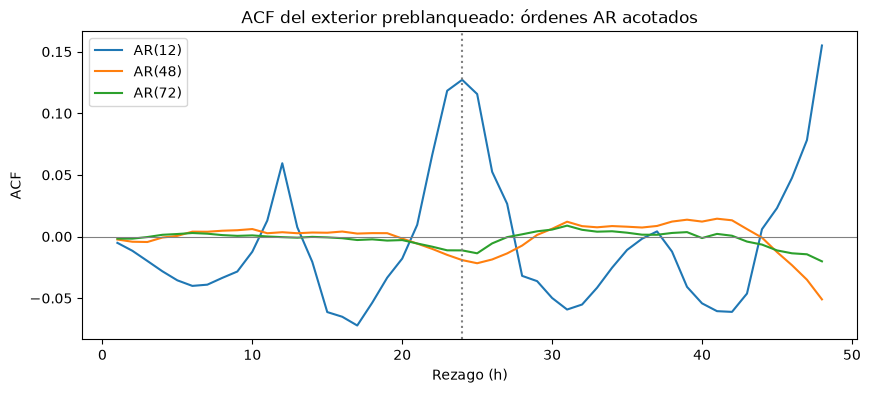

In [26]:
fig,ax=plt.subplots(figsize=(10,4))
for p in (min(CANDIDATOS_AR),p_ar_principal,max(CANDIDATOS_AR)):
    if p in residuos_ar_ext:
        ac=acf_exacta(residuos_ar_ext[p],48)
        ax.plot(ac.index,ac['acf'],label=f'AR({p})')
ax.axhline(0,color='grey',linewidth=.8)
ax.axvline(24,color='grey',linestyle=':')
ax.set_title('ACF del exterior preblanqueado: órdenes AR acotados')
ax.set_xlabel('Rezago (h)');ax.set_ylabel('ACF')
ax.legend();plt.show()



**Sensibilidad de la CCF al filtro.** Se recalculan las correlaciones cruzadas para cada orden AR sobre un soporte temporal común por condición. La comparación permite distinguir máximos relativamente estables de aquellos que se desplazan según el filtro.

In [27]:
# CCF por candidato, restringidas a exactamente el mismo conjunto de horas.
ccf_sensibilidad_ar={}
filas_sensibilidad=[]
for unidad,datos in cambios_horarios_t.items():
    filtros_int={p:aplicar_filtro_ar(datos['dT_int'],coef) for p,coef in modelos_ar_ext.items()}
    # Misma base de timestamps del exterior en todos los filtros.
    soporte_ext=residuos_ar_ext[CANDIDATOS_AR[0]].index
    soporte_int=filtros_int[CANDIDATOS_AR[0]].index
    for p in CANDIDATOS_AR[1:]:
        soporte_ext=soporte_ext.intersection(residuos_ar_ext[p].index)
        soporte_int=soporte_int.intersection(filtros_int[p].index)
    for p in CANDIDATOS_AR:
        x=residuos_ar_ext[p].loc[soporte_ext]
        y=filtros_int[p].loc[soporte_int]
        ccf=ccf_exacta(x,y,LAG_MIN_CCF,LAG_MAX_CCF)
        ccf_sensibilidad_ar[(unidad,p)]=ccf
        cr=ccf.loc[0:LAG_MAX_CCF,'correlacion'].dropna()
        if cr.empty:continue
        k=int(cr.abs().idxmax())
        filas_sensibilidad.append({'unidad':unidad,'p_AR':p,'lag_pico_abs_h':k,
                                   'ccf_firmada':float(cr.loc[k]),
                                   'n_pares_pico':int(ccf.loc[k,'n_pares'])})

sensibilidad_ar_t=pd.DataFrame(filas_sensibilidad).set_index(['unidad','p_AR']).sort_index()
print('Sensibilidad de la CCF al orden AR, sobre soporte temporal comparable:')
display(sensibilidad_ar_t.round(4))

Sensibilidad de la CCF al orden AR, sobre soporte temporal comparable:


lag_pico_abs_h  ccf_firmada  n_pares_pico
unidad p_AR                                           
H1     12                 7       0.0586          8573
       24                15       0.0846          8565
       48                15       0.0851          8565
       72                15       0.0831          8565
H2-1   12                32       0.0692          2207
       24                 0       0.0754          2239
       48                32       0.0834          2207
       72                32       0.0822          2207
H2-2   12                 6       0.1017          6204
       24                 6       0.0792          6204
       48                 8       0.0806          6204
       72                 8       0.0811          6204
H3     12                 4       0.0434          7454
       24                22       0.0485          7436
       48                32       0.0473          7426
       72                32       0.0483          7426
H4     12                27       0.0776          7284
       24                15       0.1024          7296
       48                15       0.1018          7296
       72                15       0.1027          7296

La comparación de sensibilidad utiliza las mismas fechas para todos los órdenes AR, por lo que los máximos pueden diferir ligeramente de los obtenidos inicialmente con el filtro seleccionado.

**Diagnóstico complementario a rezagos largos.** Se examinan las autocorrelaciones residuales hasta 144 horas y se aplican contrastes de Ljung–Box ajustados por el orden AR. También se verifica la estabilidad del filtro mediante sus raíces.

In [28]:
filas = []

for p in CANDIDATOS_AR:

    residuo = bloque_mas_largo(residuos_ar_ext[p])
    coef = np.asarray(modelos_ar_ext[p], dtype=float)

    rho = acf(residuo, nlags=144, fft=True)

    lb = acorr_ljungbox(
        residuo,
        lags=[96, 144],
        model_df=p,
        return_df=True
    )

    # Polinomio AR: 1 - phi_1 B - ... - phi_p B^p
    raices = np.polynomial.polynomial.polyroots(
        np.r_[1.0, -coef]
    )

    filas.append({
        "orden_AR": p,
        "n": len(residuo),
        "BIC": float(
            tabla_bic_ext.loc[
                tabla_bic_ext["p"] == p, "bic"
            ].iloc[0]
        ),
        "ACF_max_1_48": np.max(np.abs(rho[1:49])),
        "ACF_max_49_96": np.max(np.abs(rho[49:97])),
        "ACF_max_97_144": np.max(np.abs(rho[97:145])),
        "LB_96_p_ajustado": lb.loc[96, "lb_pvalue"],
        "LB_144_p_ajustado": lb.loc[144, "lb_pvalue"],
        "raiz_AR_min": np.min(np.abs(raices)),
        "AR_estable": bool(np.all(np.abs(raices) > 1))
    })

diagnostico_final_ar = (
    pd.DataFrame(filas)
    .set_index("orden_AR")
    .sort_index()
)

display(diagnostico_final_ar.round(5))


,n,BIC,ACF_max_1_48,ACF_max_49_96,ACF_max_97_144,LB_96_p_ajustado,LB_144_p_ajustado,raiz_AR_min,AR_estable
orden_AR,,,,,,,,,
12,8892,-5341.72428,0.15423,0.14994,0.11977,0.0,0.0,1.08539,True
24,8880,-6038.02716,0.06646,0.07613,0.03662,0.0,0.0,1.01731,True
48,8856,-6113.03300,0.05074,0.05377,0.02499,0.0,0.0,1.00630,True
72,8832,-6045.51255,0.02000,0.04451,0.02754,0.0,0.0,1.00295,True


El **AR(48)** presenta el menor BIC entre los órdenes evaluados, mientras que el **AR(72)** logra una mayor reducción de la autocorrelación residual. Con AR(48), las autocorrelaciones absolutas máximas son aproximadamente 0,019 en los primeros 24 rezagos y 0,051 entre los rezagos 25 y 48.

Los diagnósticos ampliados muestran que persiste cierta dependencia residual. Por lo tanto, el filtro reduce considerablemente la autocorrelación exterior, aunque no elimina completamente su estructura temporal.

La comparación de CCF por orden evidencia que algunos máximos son relativamente estables (por ejemplo, H1 y H4 alrededor de 15 h para AR(24), AR(48) y AR(72)), mientras que otros cambian de ubicación (H2-1 y H3). Por eso los máximos deben leerse como resúmenes exploratorios dependientes del filtro, y no como estimaciones definitivas de un retraso físico.


### 3.7 Correlaciones cruzadas preblanqueadas

Se presentan las CCF completas para las cinco condiciones, utilizando el filtro AR seleccionado. Las curvas permiten comparar la forma de la asociación e identificar si existen varios rezagos con correlaciones de magnitud semejante.

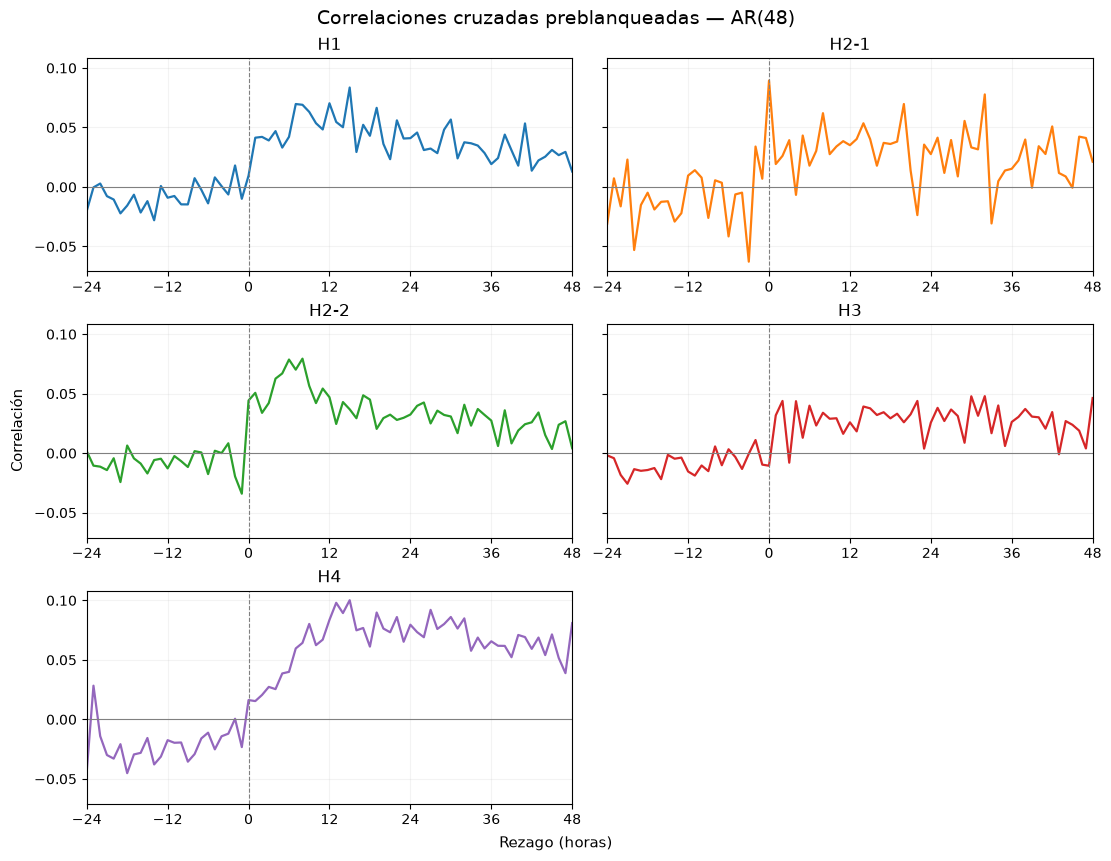

In [29]:
fig, axes = plt.subplots(3, 2, figsize=(11, 8.5), sharex=True, sharey=True,
                         layout="constrained")
colores = plt.rcParams["axes.prop_cycle"].by_key()["color"]

for i, (unidad, ccf) in enumerate(ccf_preblanqueada_t.items()):
    ax = axes.flat[i]
    ax.plot(ccf.index, ccf["correlacion"], color=colores[i], lw=1.6)
    ax.axhline(0, color="gray", lw=0.8)
    ax.axvline(0, color="gray", ls="--", lw=0.8)
    ax.set(title=unidad, xlim=(LAG_MIN_CCF, LAG_MAX_CCF))
    ax.set_xticks([-24, -12, 0, 12, 24, 36, 48])
    ax.tick_params(labelbottom=True, labelsize=10)
    ax.grid(alpha=0.15)

for ax in axes.flat[len(ccf_preblanqueada_t):]:
    ax.remove()

fig.suptitle("Correlaciones cruzadas preblanqueadas — AR(48)", fontsize=14)
fig.supxlabel("Rezago (horas)", fontsize=11)
fig.supylabel("Correlación", fontsize=11)

plt.show()

Las curvas muestran asociaciones de magnitud reducida, con diferencias en su distribución entre rezagos según la condición de medición. En varios casos se observan correlaciones de magnitud semejante en rezagos próximos, por lo que el máximo individual no resume completamente la relación temporal.

Junto con los resultados de sensibilidad al orden AR, esto limita la interpretación de los máximos como tiempos específicos de inercia térmica.

### 3.8 Resumen descriptivo de las CCF

Para visualizar los rasgos compartidos se calculan la mediana y el rango intercuartílico de las correlaciones de las cinco condiciones en cada rezago.

Este resumen es **descriptivo**: las condiciones no son réplicas independientes, comparten la misma serie exterior y H2 aporta dos períodos de medición diferentes. La figura complementa las CCF individuales y no sustituye su interpretación.


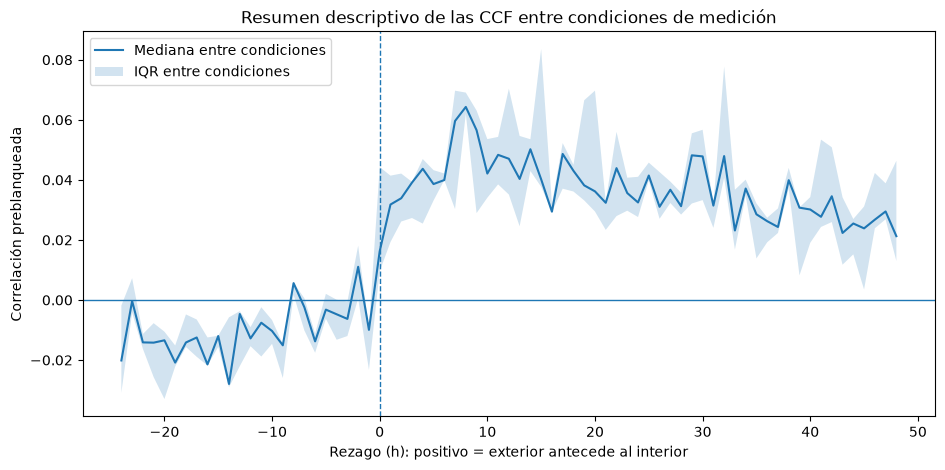

In [30]:
ccf_comun = pd.concat(
    {
        unidad: ccf["correlacion"]
        for unidad, ccf in ccf_preblanqueada_t.items()
    },
    axis=1,
    sort=False,
)

resumen_ccf_comun = pd.DataFrame({
    "mediana": ccf_comun.median(axis=1),
    "q25": ccf_comun.quantile(0.25, axis=1),
    "q75": ccf_comun.quantile(0.75, axis=1),
})

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(
    resumen_ccf_comun.index,
    resumen_ccf_comun["mediana"],
    label="Mediana entre condiciones",
)

ax.fill_between(
    resumen_ccf_comun.index,
    resumen_ccf_comun["q25"],
    resumen_ccf_comun["q75"],
    alpha=0.2,
    label="IQR entre condiciones",
)

ax.axhline(0, linewidth=1)
ax.axvline(0, linestyle="--", linewidth=1)

ax.set_xlabel("Rezago (h): positivo = exterior antecede al interior")
ax.set_ylabel("Correlación preblanqueada")
ax.set_title("Resumen descriptivo de las CCF entre condiciones de medición")
ax.legend()

plt.show()


La mediana de las correlaciones presenta valores predominantemente positivos en los rezagos posteriores a cero, sin concentrarse en un único máximo claramente definido. Las diferencias entre condiciones impiden identificar un retraso común que describa la respuesta térmica de toda la reserva.

## 4. Síntesis del análisis interior–exterior

### 4.1 Principales hallazgos

1. **Las temperaturas interiores son generalmente superiores a las exteriores, aunque la diferencia varía a lo largo del monitoreo.** Las medianas de $T^{int}-T^{ext}$ son positivas en las cinco condiciones de medición, con valores entre 2,10 y 3,59 °C. La separación también presenta variaciones mensuales.

2. **Las fluctuaciones interiores son menores que las exteriores en los horizontes examinados.** Esta diferencia se observa entre 1 y 24 horas, aunque su magnitud depende de la condición y del horizonte considerado. A escalas cortas, la granularidad de los registros térmicos condiciona especialmente las medidas de variabilidad interior.

3. **La asociación contemporánea depende de la escala temporal y del punto de medición.** Las correlaciones entre cambios horarios interiores y exteriores son pequeñas, mientras que en algunas condiciones aumentan al considerar variaciones de 24 horas.

4. **La diferenciación horaria reduce la persistencia, pero las variaciones exteriores conservan dependencia temporal.** El preblanqueo mediante un filtro AR(48), seleccionado por BIC, permite reducir considerablemente esta dependencia antes del análisis de correlaciones cruzadas, aunque no la elimina completamente.

5. **Las CCF preblanqueadas muestran asociaciones de magnitud reducida y distribuidas entre distintos rezagos.** Los máximos difieren entre condiciones y algunos son sensibles al orden del filtro AR. Si bien se observan correlaciones predominantemente positivas en los rezagos en los que el exterior antecede al interior, no se identifica un retraso único que describa el comportamiento térmico de toda la reserva.

### 4.2 Alcance e interpretación

El análisis realizado para el Objetivo 2 caracteriza distintos aspectos de la relación térmica interior–exterior mediante la comparación de niveles, fluctuaciones y asociaciones contemporáneas y rezagadas.

Los resultados permiten reconocer diferencias entre puntos de medición y describir cómo se distribuyen las asociaciones temporales con el exterior. Sin embargo, las correlaciones cruzadas no permiten cuantificar por sí solas un tiempo físico de inercia térmica ni distinguir completamente la persistencia propia del ambiente interior de su relación con las variaciones exteriores.

La interpretación también debe considerar que H2-1 y H2-2 corresponden a períodos estacionales diferentes y que la temperatura registrada por el SMN puede no representar completamente las condiciones meteorológicas locales de la reserva.

## 5. Referencias

- Scoccimarro, M. (2024). Implementación de un sistema de monitoreo ambiental orientado al diseño de estrategias sostenibles para la conservación preventiva de colecciones patrimoniales: Caso de estudio: Reserva Infanta Isabel del Museo de Artes Plásticas Eduardo Sívori [Tesina de licenciatura]. Universidad Nacional de San Martín. https://ri.unsam.edu.ar/handle/123456789/3274
